# Structure and function in the same locations

Example 2 of the paper: where a vertex's structural and functional connectivity are alike, and how
that varies inside a familiar region.

A subject's structural and functional connectomes, on one grid, give every vertex two profiles over
the cortex: the density of streamlines between it and each other vertex (SC), and the correlation of
its resting-state signal with each other vertex's (FC). Structure-function coupling at the vertex is
the cosine of the angle between the two -- their inner product over the product of their lengths,
the 2021 paper's global form, `sc.coupling(fc)` -- and, taken over the vertex's own region alone,
its region-restricted form. This notebook computes both for the eleven example subjects of the HCP
Young Adult cohort, subject A first, and follows the paper's Example 2:

- **Question.** Where are SC and FC profiles similar, and how does coupling vary within a familiar
  region?
- **Input.** The eleven subjects' SC and FC, on one grid with one mask, as `fetch_cohort` downloads
  them (section 1).
- **Choices.** Global or region-restricted coupling (section 3); negative FC kept, as the reference
  implementation keeps it, or set to zero (section 7); the FC nuisance model, with the global signal
  regressed out as released or not (section 8).
- **Output.** Subject A's SC and FC profiles at one vertex (section 2), its global and
  region-restricted maps (3), the eleven subjects' mean map (4), and the pattern inside the
  precentral gyrus (5).
- **Interpretation.** How much of the cingulate's low coupling is its nearness to the medial wall
  (section 6).
- **Sensitivity.** Negative FC set to zero (section 7), and FC rebuilt without global signal
  regression (section 8).

Section 8 reads FC that the download does not include, rebuilt from the HCP's resting-state runs;
without it the section says what it needs, and the rest runs as it is. As it stands the notebook
runs in three to four minutes on four cores of a Longleaf node, most of it computing coupling, with
5 GB of memory at its peak.

In [1]:
import itertools
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap
from scipy import sparse
from scipy.stats import spearmanr

import sbci
from sbci.coupling import discrete_coupling
from sbci.download import fetch_cohort

# The lab's copies on Longleaf; point these at your own files. Only section 8 reads NO_GSR, the
# eleven subjects' FC rebuilt without global signal regression (tools/build_hcp_fc.py --no-gsr);
# everything else reads what fetch_cohort() downloads into ./hcp-ya.
NO_GSR = Path("/work/users/x/y/xya/paper-open-items/fc_nogsr")  # sub-<id>_fc.h5, one a subject

# The package's figure style: one blue for the continuous connectome, orange for the atlas.
BLUE, ORANGE, INK, MUTED, RULE = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#d9d8d3"
BLUE_RAMP = LinearSegmentedColormap.from_list(
    "blue", ["#f4f8fd", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
)
SURFACE_RAMP = LinearSegmentedColormap.from_list(
    "surface", ["#b7d3f6", "#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281", "#0d366b"]
)
# For a map with a sign, FC above all: blue below zero, red above it, grey at zero.
DIVERGING = LinearSegmentedColormap.from_list(
    "diverging", ["#0d366b", "#2a78d6", "#9ec5f4", "#f0efec", "#f2a3a3", "#e34948", "#8e1f22"]
)
plt.rcParams.update({
    "font.size": 10, "text.color": INK, "axes.labelcolor": MUTED, "axes.edgecolor": RULE,
    "axes.spines.top": False, "axes.spines.right": False, "xtick.color": MUTED,
    "ytick.color": MUTED, "figure.facecolor": "white", "figure.dpi": 110,
})


def surface(values, title, scale=None, cmap=SURFACE_RAMP, threshold=None,
            views=("lateral", "medial")):
    """A map on fsaverage, as the package's figures are drawn, but a quarter smaller.

    ``scale`` fixes the colour range; without it the map is coloured over its own 2nd to 98th
    percentile. ``DIVERGING`` maps are centred on zero, and ``threshold`` leaves the values nearer
    zero than it uncoloured, so that the folds show through. The smaller size keeps this file small.
    """
    if scale is None:
        scale = tuple(float(v) for v in np.round(np.nanpercentile(values, [2, 98]), 2))
    figure = sbci.plot_surface(
        values, cmap=cmap, symmetric=cmap is DIVERGING, vmin=scale[0], vmax=scale[1],
        threshold=threshold, title=title, views=views, mesh="fsaverage", engine="pyvista",
    )
    figure.set_size_inches(0.75 * figure.get_size_inches())
    return figure


desikan = sbci.load_atlas("Desikan")
cortex = sbci.atlas.cortex_mask()  # False on the medial wall, which carries no cortex


def region_of(vertex):
    """The name of the Desikan region a vertex lies in."""
    return desikan.names[desikan.labels[vertex] - 1]


def extremes(values, label, count=6):
    """The Desikan regions where a map is highest and lowest, by its mean over each; the means."""
    means = sbci.region_means(values, desikan)
    order = np.argsort(means)
    for word, chosen in (("highest", order[::-1][:count]), ("lowest", order[:count])):
        listed = ", ".join(f"{desikan.names[i]} {means[i]:.2f}" for i in chosen)
        print(f"{label}, {word}: {listed}")
    return means


# Primary and unimodal sensory and motor regions, and association regions, as the package's
# coupling figures group the Desikan regions (scripts/hcp_figures.py); the insula, the temporal
# pole and the other regions are in neither group.
UNIMODAL = ("precentral", "postcentral", "paracentral", "pericalcarine", "cuneus", "lingual",
            "lateraloccipital", "transversetemporal", "superiortemporal")
ASSOCIATION = ("inferiorparietal", "supramarginal", "precuneus", "superiorfrontal",
               "rostralmiddlefrontal", "caudalmiddlefrontal", "medialorbitofrontal",
               "lateralorbitofrontal", "middletemporal", "inferiortemporal", "posteriorcingulate",
               "isthmuscingulate", "rostralanteriorcingulate")
unimodal = np.array([name[3:] in UNIMODAL for name in desikan.names])
association = np.array([name[3:] in ASSOCIATION for name in desikan.names])
print(f"{cortex.sum():,} cortical vertices of {cortex.size:,}; {unimodal.sum()} primary and "
      f"unimodal Desikan regions and {association.sum()} association regions of "
      f"{desikan.n_regions}")

4,685 cortical vertices of 5,124; 18 primary and unimodal Desikan regions and 26 association regions of 68


## 1. The eleven subjects

`fetch_cohort`, as in the paper's listing, downloads the eleven example subjects into `hcp-ya/`, 22
files, 1.00 GB, once the HCP's data use terms have been accepted on the machine (`accept_terms=True`
accepts them; read them first), and checks every file's SHA-256 against the package's index. Files
already there, as here, are verified and kept. It returns the files in the index's order, each
subject's SC before its FC, subject A first. All 22 share one grid of 5,124 vertices and one mask,
4,685 of them cortex. The FC comes from the HCP's ICA-FIX-cleaned resting state, four runs (4,800
frames) for ten subjects and three (3,600) for one, with each run's global signal, a constant and a
linear trend regressed out: the nuisance model that section 8 changes.

In [2]:
paths = fetch_cohort(out="hcp-ya", accept_terms=True)  # downloads only what is missing
sc = [sbci.load(path) for path in paths[0::2]]  # each subject's SC, with its streamline endpoints
fc = [sbci.load(path) for path in paths[1::2]]  # and its FC, in the same order: subject A first
assert all((s.mask == cortex).all() and (f.mask == cortex).all()  # one grid and one mask
           for s, f in zip(sc, fc, strict=True))
size = sum(path.stat().st_size for path in paths) / 1e9
print(f"{len(paths)} files, {size:.2f} GB: {len(sc)} subjects' SC and FC, on one grid of "
      f"{cortex.size:,} vertices with one mask, {cortex.sum():,} of them cortex")
made = Counter((len(f.metadata.get("fc_runs")), int(f.metadata.get("fc_frames"))) for f in fc)
print("FC from " + "; ".join(f"{runs} runs, {frames:,} frames ({count} subject{'s' * (count > 1)})"
                             for (runs, frames), count in sorted(made.items(), reverse=True)))
print("FC nuisance model:", fc[0].metadata.get("fc_nuisance_model"))

  these data come with terms of use: read hcp-ya/DATA_USE.txt
  sub-100307_sc.h5: present and verified


  sub-100307_fc.h5: present and verified
  sub-103010_sc.h5: present and verified


  sub-103010_fc.h5: present and verified
  sub-108121_sc.h5: present and verified


  sub-108121_fc.h5: present and verified
  sub-116221_sc.h5: present and verified


  sub-116221_fc.h5: present and verified
  sub-137431_sc.h5: present and verified


...

  sub-212116_fc.h5: present and verified
  sub-386250_sc.h5: present and verified


  sub-386250_fc.h5: present and verified
  sub-679770_sc.h5: present and verified


  sub-679770_fc.h5: present and verified
  sub-729557_sc.h5: present and verified


  sub-729557_fc.h5: present and verified


22 files, 1.00 GB: 11 subjects' SC and FC, on one grid of 5,124 vertices with one mask, 4,685 of them cortex
FC from 4 runs, 4,800 frames (10 subjects); 3 runs, 3,600 frames (1 subject)
FC nuisance model: HCP minimal preprocessing and ICA-FIX (rfMRI *_Atlas_hp2000_clean); per run, the global signal, a constant and a linear trend regressed out; grid-vertex mean time series z-scored and the runs concatenated


## 2. What coupling compares: one vertex's two profiles

Coupling compares two rows of two matrices. The vertex here is 842, half-way up subject A's left
precentral gyrus (half of the gyrus's 169 vertices lie below it), the region of section 5, rather
than Example 1's vertex 1234 in the banks of the superior temporal sulcus. Its SC profile,
`sc.seed(vertex=842)`, is the density of streamlines between it and every other vertex, drawn below
on a logarithmic scale relative to its largest value. It is at least a thousandth of that peak over
32% of the cortex and is zero over 43%; 30% of its mass lies in the precentral gyrus itself, 24% in
the postcentral gyrus and 16% in the superior parietal lobule, and 8% in the right precentral gyrus.
Its FC profile, `fc.seed(vertex=842)`, is the correlation of the vertex's signal with every other
vertex's. It runs from -0.18 to 0.40, the largest 4.4 mm away in the same gyrus, but over the gyrus
as a whole it averages only 0.04: by region it is highest in the cuneus (0.08 on both sides) and the
left lateral occipital cortex (0.06), and 41% of the cortex correlates with the vertex negatively,
the global signal having been regressed out. It is drawn where it is at least 0.05 from zero. The
cosine of the two rows is 0.185, the value of subject A's global coupling map at vertex 842 (section
3); their Pearson correlation, which centres both rows first, is 0.162. Of their inner product, 66%
comes from the precentral gyrus itself, which is all that the region-restricted form compares. The
grey dot in the left precentral gyrus is the vertex itself: neither profile holds its connection
with itself.

vertex 842: LH_precentral; 50% of the region's 169 vertices lie below it
SC profile: at least a thousandth of its peak at 32% of the cortex, zero at 43%
  its mass by region: LH_precentral 30%, LH_postcentral 24%, LH_superiorparietal 16%, RH_precentral 8%, LH_inferiorparietal 6%, RH_superiorfrontal 4%
FC profile: -0.18 to 0.40, the largest at vertex 42 in LH_precentral, 4.4 mm from vertex 842; below zero at 41% of the cortex
  its mean by region, highest: RH_cuneus 0.08, LH_cuneus 0.08, LH_lateraloccipital 0.06, RH_pericalcarine 0.05, RH_supramarginal 0.05, LH_superiorparietal 0.05; over the vertex's own region 0.04
cosine of the two rows 0.185; Pearson's r 0.162; from the vertex's own region, 66% of their inner product


[fetch_surf_fsaverage] Dataset directory found: /nas/longleaf/home/xya/nilearn_data/fsaverage


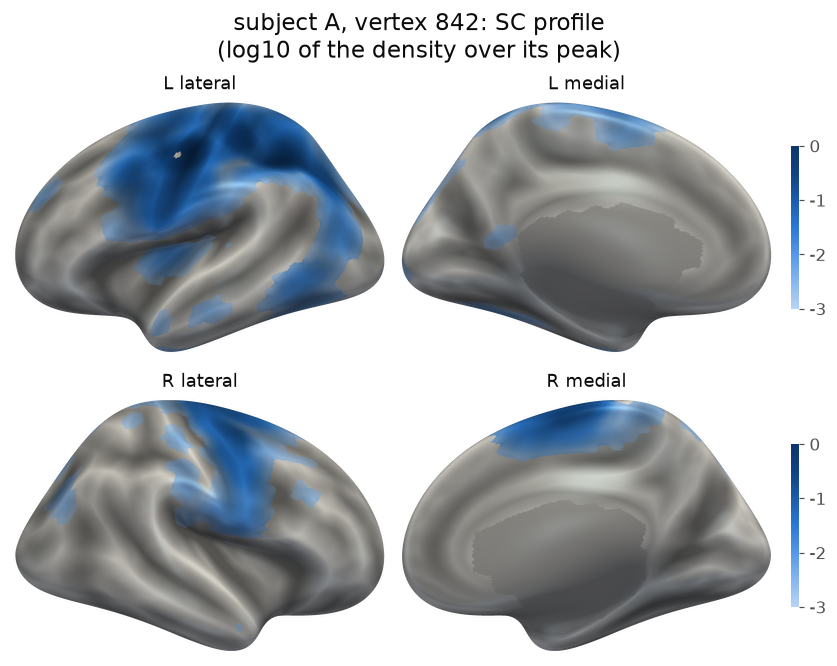

In [3]:
SEED = 842  # half-way up the left precentral gyrus
white = sbci.load_surface("white").vertices  # millimetres, in fsaverage's space
height = white[:, 2]  # inferior to superior
own = desikan.labels == desikan.labels[SEED]  # the vertex's own Desikan region
lower = np.mean(height[own & cortex] < height[SEED])
print(f"vertex {SEED}: {region_of(SEED)}; {lower:.0%} of the region's {np.sum(own & cortex)} "
      "vertices lie below it")

structural = sc[0].seed(vertex=SEED)  # subject A's row of SC: a density, zero at the vertex itself
functional = fc[0].seed(vertex=SEED)  # and of FC: Pearson's r, zero at the vertex itself
relative = structural / structural.max()
print(f"SC profile: at least a thousandth of its peak at {np.mean(relative[cortex] >= 1e-3):.0%} "
      f"of the cortex, zero at {np.mean(structural[cortex] == 0):.0%}")
mass = np.bincount(desikan.labels, structural * sc[0].area, desikan.n_regions + 1)[1:]
share = mass / mass.sum()
listed = ", ".join(f"{desikan.names[i]} {share[i]:.0%}" for i in np.argsort(share)[::-1][:6])
print(f"  its mass by region: {listed}")
by_region = sbci.region_means(functional, desikan)
largest = int(np.argmax(np.where(cortex, functional, -np.inf)))
apart = np.linalg.norm(white[largest] - white[SEED])
print(f"FC profile: {np.min(functional[cortex]):.2f} to {np.max(functional[cortex]):.2f}, the "
      f"largest at vertex {largest} in {region_of(largest)}, {apart:.1f} mm from vertex {SEED}; "
      f"below zero at {np.mean(functional[cortex] < 0):.0%} of the cortex")
order = np.argsort(by_region)[::-1][:6]
listed = ", ".join(f"{desikan.names[i]} {by_region[i]:.2f}" for i in order)
print(f"  its mean by region, highest: {listed}; over the vertex's own region "
      f"{by_region[desikan.labels[SEED] - 1]:.2f}")

cosine = structural @ functional / (np.linalg.norm(structural) * np.linalg.norm(functional))
pearson = np.corrcoef(structural[cortex], functional[cortex])[0, 1]
inner = structural[own] @ functional[own] / (structural @ functional)
print(f"cosine of the two rows {cosine:.3f}; Pearson's r {pearson:.3f}; from the vertex's own "
      f"region, {inner:.0%} of their inner product")

reach = np.where(cortex & (relative >= 1e-3), np.log10(np.maximum(relative, 1e-300)), np.nan)
title = f"subject A, vertex {SEED}: SC profile\n(log10 of the density over its peak)"
figure = surface(reach, title, scale=(-3, 0))

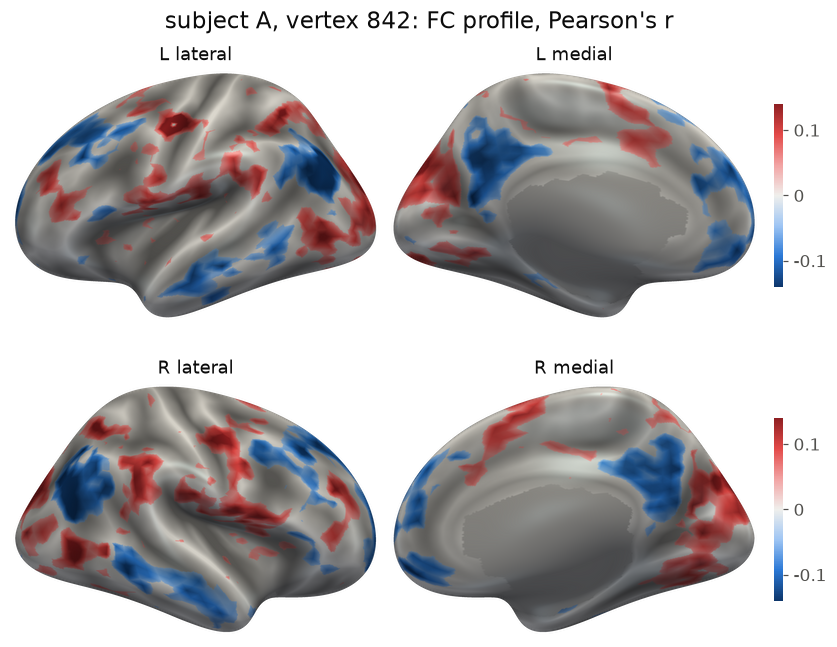

In [4]:
limit = float(np.round(np.percentile(np.abs(functional[cortex]), 98), 2))
title = f"subject A, vertex {SEED}: FC profile, Pearson's r"
figure = surface(np.where(cortex, functional, np.nan), title, scale=(-limit, limit),
                 cmap=DIVERGING, threshold=0.05)

## 3. Subject A's coupling maps: over the surface, inside each region, between regions

Done at every vertex, the comparison gives the global map, `sc.coupling(fc)`. Subject A's averages
0.217 over the cortex and runs from -0.12 to 0.54: negative FC is kept, as the reference
implementation keeps it, and 1.7% of the cortical vertices come out below zero. The
region-restricted form, `scope="region"` with the Desikan labels, compares the two rows over the
vertex's own region alone. It averages 0.595, higher because neighbouring vertices in a region share
both structure and function, and it is undefined at the 11 vertices of the two frontal poles,
regions of fewer than ten vertices. Elsewhere both forms give a value at each vertex; the atlas only
sets the second's neighbourhood. The third, `discrete_coupling`, compares rows of the Desikan
matrices themselves, SC's mean density (`to_atlas(how="mean")`) against FC's mean correlation, and
it is a Pearson correlation rather than a cosine: 0.364 on average over the 68 regions. In the
figures the medial wall, which has no profile, is grey.

global: mean 0.217, -0.12 to 0.54; 1.7% of the cortical vertices below zero; 0.185 at vertex 842
within regions: mean 0.595; undefined at 11 cortical vertices, in LH_frontalpole and RH_frontalpole
between Desikan regions: mean 0.364 over 68 regions


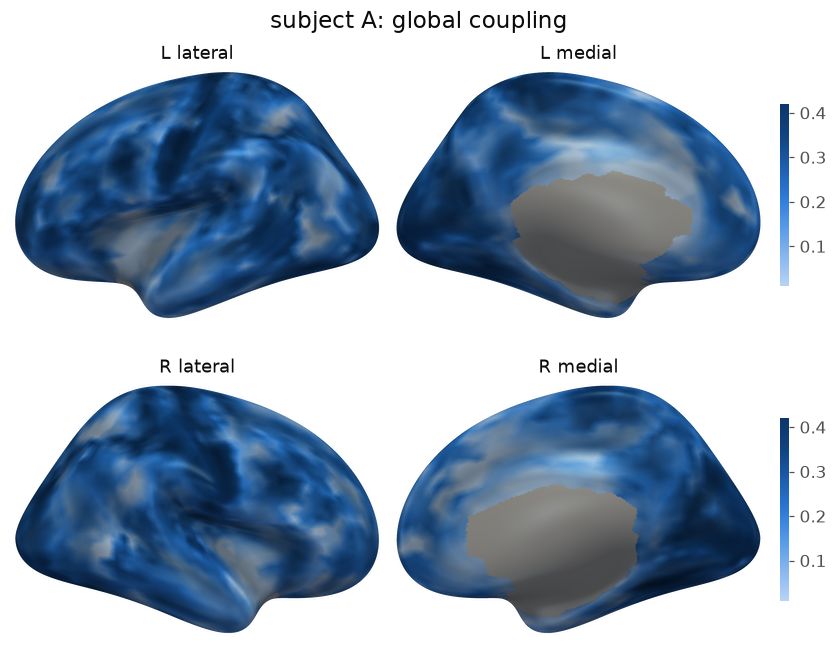

In [5]:
whole = sc[0].coupling(fc[0])  # global: each vertex's two rows over the whole surface
local = sc[0].coupling(fc[0], scope="region", labels=desikan.labels)  # over its own region
# between regions: rows of the two Desikan matrices, one value a region
between = discrete_coupling(sc[0].to_atlas(desikan, how="mean"), fc[0].to_atlas(desikan))
print(f"global: mean {np.nanmean(whole):.3f}, {np.nanmin(whole):.2f} to {np.nanmax(whole):.2f}; "
      f"{np.mean(whole[cortex] < 0):.1%} of the cortical vertices below zero; {whole[SEED]:.3f} at "
      f"vertex {SEED}")
undefined = cortex & np.isnan(local)
where = " and ".join(sorted({desikan.names[k - 1] for k in desikan.labels[undefined]}))
print(f"within regions: mean {np.nanmean(local):.3f}; undefined at {undefined.sum()} cortical "
      f"vertices, in {where}")
print(f"between Desikan regions: mean {np.nanmean(between):.3f} over {between.size} regions")
figure = surface(whole, "subject A: global coupling")

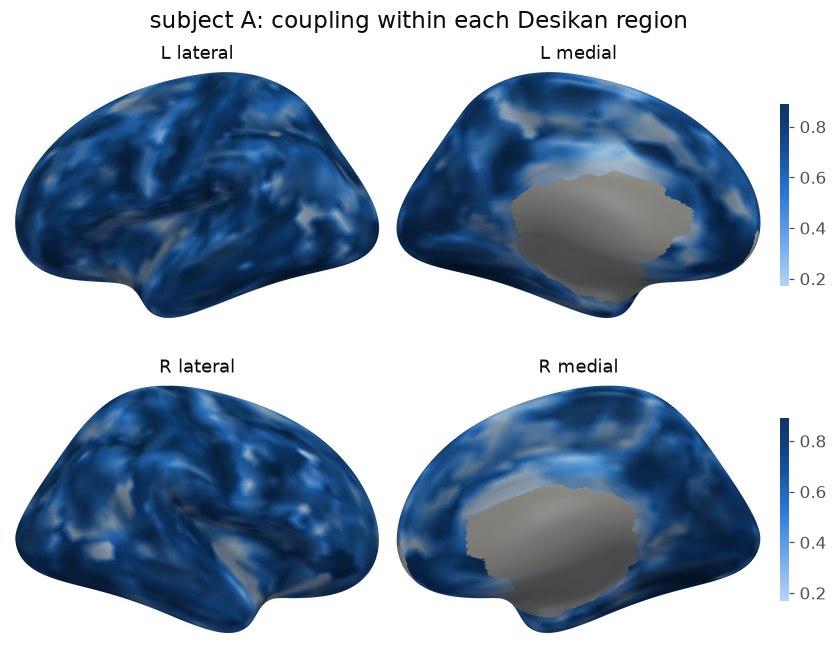

In [6]:
figure = surface(local, "subject A: coupling within each Desikan region")

## 4. The eleven subjects: where coupling is high and where it is low

Subject by subject, global coupling averages 0.200 to 0.268, region-restricted coupling 0.595 to
0.679 and the Desikan-level form 0.329 to 0.421. Averaged over the eleven, the global map is highest
in visual cortex -- the right lateral occipital cortex 0.41, the right cuneus 0.39, the
pericalcarine cortex 0.38 on the right and 0.36 on the left, the left cuneus and lateral occipital
cortex 0.37 -- and lowest in the cingulate and entorhinal cortex: the caudal anterior cingulate 0.05
and 0.06, the right entorhinal cortex 0.08, the posterior cingulate 0.09 on both sides and the left
entorhinal cortex 0.09. Over the 18 primary and unimodal sensory and motor regions it averages 0.30,
against 0.19 over the 26 association regions. The subjects' maps correlate with one another at r =
0.53 to 0.71 (median 0.61): a shared pattern, from which each subject departs.

global: the subjects' means 0.200 to 0.268
within regions: the subjects' means 0.595 to 0.679
between Desikan regions: the subjects' means 0.329 to 0.421
the eleven's mean, highest: RH_lateraloccipital 0.41, RH_cuneus 0.39, RH_pericalcarine 0.38, LH_cuneus 0.37, LH_lateraloccipital 0.37, LH_pericalcarine 0.36
the eleven's mean, lowest: LH_caudalanteriorcingulate 0.05, RH_caudalanteriorcingulate 0.06, RH_entorhinal 0.08, LH_posteriorcingulate 0.09, RH_posteriorcingulate 0.09, LH_entorhinal 0.09
primary and unimodal regions 0.30 on average, association regions 0.19
the subjects' maps against one another: r = 0.53 to 0.71 (median 0.61)


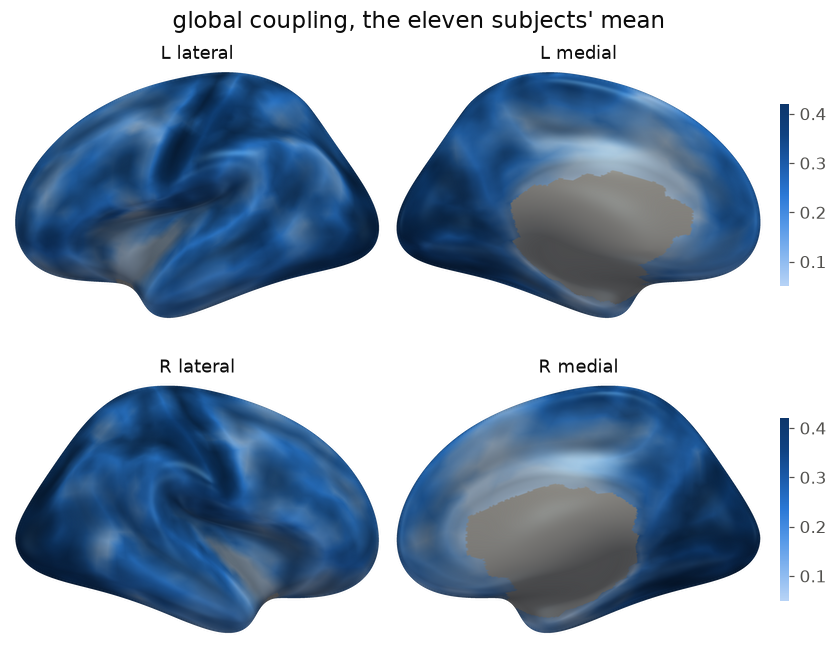

In [7]:
maps = {"global": [], "within regions": [], "between Desikan regions": []}
for s, f in zip(sc, fc, strict=True):
    maps["global"].append(s.coupling(f))
    maps["within regions"].append(s.coupling(f, scope="region", labels=desikan.labels))
    regional = s.to_atlas(desikan, how="mean"), f.to_atlas(desikan)
    maps["between Desikan regions"].append(discrete_coupling(*regional))
maps = {name: np.vstack(values) for name, values in maps.items()}
for name, values in maps.items():
    means = np.nanmean(values, axis=1)
    print(f"{name}: the subjects' means {means.min():.3f} to {means.max():.3f}")

coupling = maps["global"]  # (11, 5124): NaN on the medial wall and nowhere else
mean_map = np.full(cortex.size, np.nan)
mean_map[cortex] = coupling[:, cortex].mean(axis=0)
regions = extremes(mean_map, "the eleven's mean")
print(f"primary and unimodal regions {regions[unimodal].mean():.2f} on average, association "
      f"regions {regions[association].mean():.2f}")
r = np.corrcoef(coupling[:, cortex])[np.triu_indices(len(sc), 1)]
print(f"the subjects' maps against one another: r = {r.min():.2f} to {r.max():.2f} "
      f"(median {np.median(r):.2f})")
figure = surface(mean_map, "global coupling, the eleven subjects' mean")

## 5. Inside the precentral gyrus

The eleven's mean map is far from flat inside a region. Across the left precentral gyrus's 169
vertices it runs from 0.141 to 0.372 (5th to 95th percentile) around a mean of 0.251, with an SD of
0.069; across the right gyrus's 167, from 0.142 to 0.355 around 0.253, SD 0.070. That is nearly the
spread between the 68 regions' means, SD 0.079 (0.080 leaving out the two frontal poles, of five and
six vertices). Coupling rises toward the dorsal end of the gyrus, correlating with height on the
white surface at r = 0.31 on the left and 0.28 on the right, though not steadily: by thirds of its
height it averages 0.240, 0.236 and 0.279 from the bottom on the left, and 0.247, 0.228 and 0.286 on
the right. And the pattern recurs from subject to subject: the median correlation between two
subjects' maps inside the gyrus is 0.52 on the left and 0.59 on the right. Over all the regions,
coupling varies inside a region a little less in association cortex than in primary and unimodal
cortex (a within-region SD of 0.041 against 0.050 on average), though more for its lower level (0.23
of the region's mean against 0.18), and the pattern inside recurs less across subjects (median r
0.29 against 0.41).

left precentral gyrus: 169 vertices, mean 0.251, 5th to 95th percentile 0.141 to 0.372, SD 0.069; r with height 0.31; between two subjects inside it, median r 0.52
  by thirds of its height, from the bottom: 0.240, 0.236, 0.279
right precentral gyrus: 167 vertices, mean 0.253, 5th to 95th percentile 0.142 to 0.355, SD 0.070; r with height 0.28; between two subjects inside it, median r 0.59
  by thirds of its height, from the bottom: 0.247, 0.228, 0.286
SD between the 68 regions' means 0.079; 0.080 without LH_frontalpole (5 vertices) and RH_frontalpole (6 vertices)
18 primary and unimodal regions: within-region SD 0.050 on average, 0.18 of the region's mean; the pattern inside recurs at median r 0.41
26 association regions: within-region SD 0.041 on average, 0.23 of the region's mean; the pattern inside recurs at median r 0.29


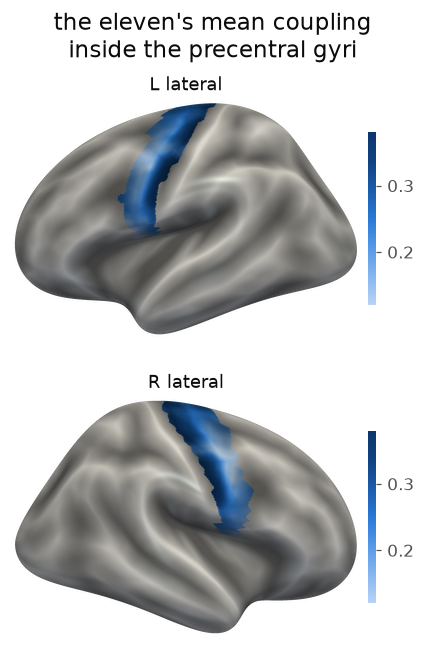

In [8]:
pairs = list(itertools.combinations(range(len(sc)), 2))
inside_region = {}
for k, name in enumerate(desikan.names):
    member = (desikan.labels == k + 1) & cortex
    values = mean_map[member]
    recurs = np.nan  # how far the pattern inside recurs: the median r between two subjects' maps
    if member.sum() >= 10:
        recurs = np.median([np.corrcoef(coupling[a, member], coupling[b, member])[0, 1]
                            for a, b in pairs])
    inside_region[name] = {
        "vertices": int(member.sum()), "mean": values.mean(), "sd": values.std(),
        "low": np.percentile(values, 5), "high": np.percentile(values, 95),
        "height": np.corrcoef(values, height[member])[0, 1], "recurs": recurs,
    }
for side, word in (("LH", "left"), ("RH", "right")):
    member = desikan.region_mask(f"{side}_precentral") & cortex
    row = inside_region[f"{side}_precentral"]
    print(f"{word} precentral gyrus: {row['vertices']} vertices, mean {row['mean']:.3f}, 5th to "
          f"95th percentile {row['low']:.3f} to {row['high']:.3f}, SD {row['sd']:.3f}; r with "
          f"height {row['height']:.2f}; between two subjects inside it, median r "
          f"{row['recurs']:.2f}")
    thirds = np.array_split(np.flatnonzero(member)[np.argsort(height[member])], 3)
    listed = ", ".join(f"{mean_map[third].mean():.3f}" for third in thirds)
    print(f"  by thirds of its height, from the bottom: {listed}")
small = [f"{name} ({row['vertices']} vertices)" for name, row in inside_region.items()
         if row["vertices"] < 10]
large = np.array([row["vertices"] >= 10 for row in inside_region.values()])
print(f"SD between the {regions.size} regions' means {regions.std():.3f}; "
      f"{regions[large].std():.3f} without " + " and ".join(small))
for label, group in (("primary and unimodal", unimodal), ("association", association)):
    rows = [row for row, chosen in zip(inside_region.values(), group, strict=True) if chosen]
    spread = np.mean([row["sd"] for row in rows])
    relative_spread = np.mean([row["sd"] / row["mean"] for row in rows])
    recurs = np.median([row["recurs"] for row in rows])
    print(f"{group.sum()} {label} regions: within-region SD {spread:.3f} on average, "
          f"{relative_spread:.2f} of the region's mean; the pattern inside recurs at median r "
          f"{recurs:.2f}")

precentral = (desikan.region_mask("LH_precentral") | desikan.region_mask("RH_precentral")) & cortex
figure = surface(np.where(precentral, mean_map, np.nan),
                 "the eleven's mean coupling\ninside the precentral gyri", views=("lateral",))

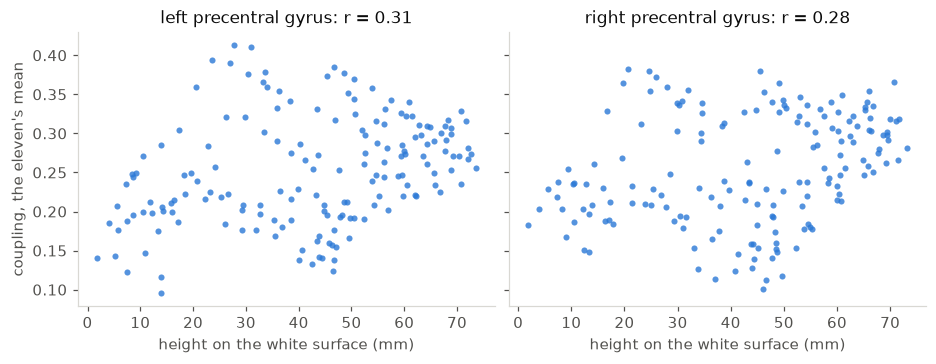

In [9]:
figure, axes = plt.subplots(1, 2, figsize=(8.4, 3.2), sharey=True, constrained_layout=True)
for axis, (side, word) in zip(axes, (("LH", "left"), ("RH", "right")), strict=True):
    member = desikan.region_mask(f"{side}_precentral") & cortex
    axis.scatter(height[member], mean_map[member], s=16, color=BLUE, alpha=0.8, linewidths=0)
    rise = inside_region[f"{side}_precentral"]["height"]
    axis.set_title(f"{word} precentral gyrus: r = {rise:.2f}", fontsize=11)
    axis.set_xlabel("height on the white surface (mm)")
axes[0].set_ylabel("coupling, the eleven's mean")
plt.show()

## 6. The cingulate and the medial wall

The lowest coupling lies beside the medial wall, and so does weak structural connectivity. Counting
grid rings outward from the wall (ring 1 touches it), a vertex's SC strength -- its row of the SC
density summed over the surface, averaged over the eleven -- is 0.22 of the cortical mean in ring 1
and 0.32 in ring 2, and passes the mean only six or more rings out (1.11). Coupling follows it:
outside the cingulate and entorhinal cortex it is 0.100 in ring 1 against 0.250 six or more rings
out, and the entorhinal cortex lies within five rings of the wall throughout. The four cingulate
regions on both sides average 0.120 against 0.240 for the rest of the cortex. The rest of the cortex
at the cingulate's distances from the wall, weighted to the cingulate's share of vertices in each
ring, averages 0.164, so 63% of the cingulate's gap (0.076 of 0.120) goes with its nearness to the
wall. At a matched distance the cingulate is still lower (0.120 against 0.164), most of all the
caudal anterior and posterior cingulate, which average 0.069 and 0.105 more than two rings from the
wall. Their low coupling owes something to where it is measured, beside a wall where structural
connectivity is weak, and not only to the cingulate.

grid rings from the medial wall              1       2       3     4-5      6+
SC strength, over the cortical mean       0.22    0.32    0.39    0.58    1.11
coupling, the rest of the cortex         0.100   0.153   0.168   0.183   0.250
coupling, the cingulate                  0.095   0.127   0.130   0.124   0.130
coupling, the entorhinal cortex          0.068   0.092   0.108   0.124       -
vertices of the cingulate, ring by ring: 58, 59, 44, 62, 35
vertices of the entorhinal cortex, ring by ring: 10, 10, 7, 1, 0
the cingulate 0.120, the rest of the cortex 0.240; the rest at the cingulate's distances 0.164: 0.076 of the gap of 0.120 (63%) goes with nearness to the wall
  caudalanteriorcingulate: 0.057; more than two rings from the wall 0.069
  rostralanteriorcingulate: 0.140; more than two rings from the wall 0.195
  posteriorcingulate: 0.090; more than two rings from the wall 0.105
  isthmuscingulate: 0.189; more than two rings from the wall 0.218


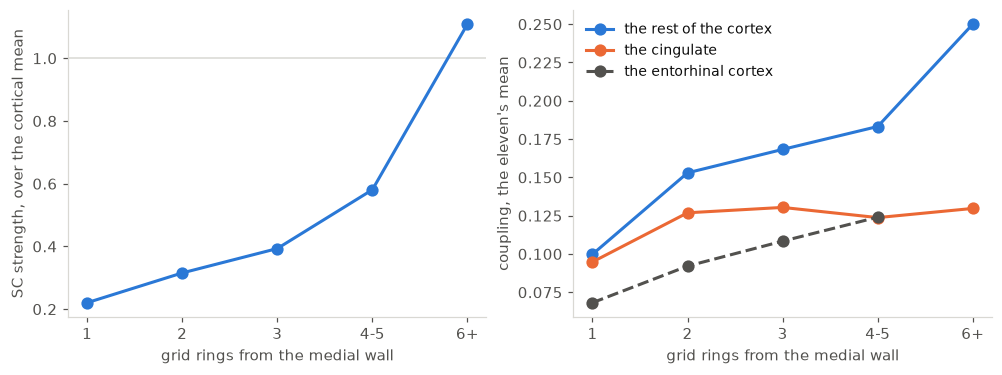

In [10]:
# Grid rings from the medial wall: ring 1 touches it, ring 2 touches ring 1, and so on.
faces = sbci.load_surface("white").faces
edges = np.vstack([faces[:, [0, 1]], faces[:, [1, 2]], faces[:, [2, 0]]])
touching = sparse.coo_matrix((np.ones(len(edges)), (edges[:, 0], edges[:, 1])),
                             shape=(cortex.size,) * 2).tocsr()
touching = ((touching + touching.T) > 0).astype(float)
ring = np.where(cortex, -1, 0)
step = 0
while (ring < 0).any():
    step += 1
    reached = (touching @ (ring >= 0).astype(float) > 0) & (ring < 0)
    ring[reached] = step
BINS = {"1": (1, 1), "2": (2, 2), "3": (3, 3), "4-5": (4, 5), "6+": (6, step)}

# SC strength: each vertex's row of the density summed over the surface, averaged over the eleven.
strength = np.mean([s.dense(np.float64) @ s.area for s in sc], axis=0)
names = np.array(desikan.names)


def regions_named(word):
    """The cortex of every Desikan region whose name holds ``word``, on both sides."""
    return cortex & np.isin(desikan.labels, 1 + np.flatnonzero(np.char.find(names, word) >= 0))


cingulate, entorhinal = regions_named("cingulate"), regions_named("entorhinal")
rest = cortex & ~cingulate & ~entorhinal
groups = {"the rest of the cortex": rest, "the cingulate": cingulate,
          "the entorhinal cortex": entorhinal}
by_ring = {"SC strength, over the cortical mean": []} | {f"coupling, {key}": [] for key in groups}
for low, high in BINS.values():
    band = (ring >= low) & (ring <= high)
    by_ring["SC strength, over the cortical mean"].append(
        strength[band & cortex].mean() / strength[cortex].mean())
    for key, group in groups.items():
        inside = band & group
        by_ring[f"coupling, {key}"].append(mean_map[inside].mean() if inside.any() else np.nan)
print(f"{'grid rings from the medial wall':38s}" + "".join(f"{label:>8s}" for label in BINS))
for label, values in by_ring.items():
    digits = 2 if label.startswith("SC") else 3
    cells = ("       -" if np.isnan(v) else f"{v:8.{digits}f}" for v in values)
    print(f"{label:38s}" + "".join(cells))
for label, group in (("the cingulate", cingulate), ("the entorhinal cortex", entorhinal)):
    counts = (np.sum(group & (ring >= low) & (ring <= high)) for low, high in BINS.values())
    print(f"vertices of {label}, ring by ring: " + ", ".join(str(count) for count in counts))

# The rest of the cortex at the cingulate's distances from the wall: as low as the cingulate, if
# the wall were all there is to it.
capped = np.minimum(ring, 6)
weights = np.bincount(capped[cingulate], minlength=7) / cingulate.sum()
at_distance = np.array([mean_map[rest & (capped == d)].mean() if (rest & (capped == d)).any()
                        else 0.0 for d in range(7)])
matched = weights @ at_distance
cingulate_mean, rest_mean = mean_map[cingulate].mean(), mean_map[rest].mean()
gap = rest_mean - cingulate_mean
print(f"the cingulate {cingulate_mean:.3f}, the rest of the cortex {rest_mean:.3f}; the rest at "
      f"the cingulate's distances {matched:.3f}: {rest_mean - matched:.3f} of the gap of {gap:.3f} "
      f"({(rest_mean - matched) / gap:.0%}) goes with nearness to the wall")
for name in ("caudalanteriorcingulate", "rostralanteriorcingulate", "posteriorcingulate",
             "isthmuscingulate"):
    member = regions_named(name)
    far = mean_map[member & (ring > 2)].mean()
    print(f"  {name}: {mean_map[member].mean():.3f}; more than two rings from the wall {far:.3f}")

figure, (left, right) = plt.subplots(1, 2, figsize=(9, 3.3), constrained_layout=True)
x = np.arange(len(BINS))
left.plot(x, by_ring["SC strength, over the cortical mean"], "o-", color=BLUE, linewidth=2,
          markersize=7)
left.axhline(1, color=RULE, linewidth=1, zorder=0)
left.set_ylabel("SC strength, over the cortical mean")
for key, colour, style in zip(groups, (BLUE, ORANGE, MUTED), ("-", "-", "--"), strict=True):
    right.plot(x, by_ring[f"coupling, {key}"], "o", linestyle=style, color=colour, linewidth=2,
               markersize=7, label=key)
right.set_ylabel("coupling, the eleven's mean")
right.legend(frameon=False, fontsize=9)
for axis in (left, right):
    axis.set_xticks(x, list(BINS))
    axis.set_xlabel("grid rings from the medial wall")
plt.show()

## 7. Sensitivity: negative FC set to zero

With the global signal regressed out, about half of each subject's FC is negative, 46% to 53% of the
pairs of cortical vertices. Kept, as the reference implementation keeps it, negative FC gives 0.5%
to 1.7% of a subject's cortical vertices a negative coupling. Set to zero, it raises coupling at
every cortical vertex of every subject, as it must: SC is never negative (its smallest entry is 0),
so the terms dropped from the inner product could only lower it, and dropping them shortens FC's row
as well. The subjects' means rise from 0.200-0.268 to 0.307-0.355, and the pattern stays: each
subject's map correlates with its map with negative FC kept at r = 0.885 to 0.957 (median 0.937),
and the eleven's mean maps at 0.952. Primary and unimodal regions stay above association regions,
0.38 against 0.30 on average; the occipital cortex stays highest (the right lateral occipital cortex
0.50) and the entorhinal and caudal anterior cingulate cortex lowest (0.14 to 0.18).

FC below zero: 46% to 53% of the pairs of cortical vertices; SC's smallest entry 0
negative FC kept: 0.5% to 1.7% of a subject's cortical vertices have negative coupling


set to zero: coupling higher at 51,535 of the 51,535 cortical vertices of the eleven; the subjects' means 0.307 to 0.355
each subject's map against its map with negative FC kept: r = 0.885 to 0.957 (median 0.937)
the eleven's mean maps: r = 0.952
negative FC set to zero, highest: RH_lateraloccipital 0.50, RH_cuneus 0.46, RH_pericalcarine 0.45, LH_lateraloccipital 0.45, LH_pericalcarine 0.43, LH_cuneus 0.43
negative FC set to zero, lowest: RH_entorhinal 0.14, LH_entorhinal 0.15, LH_caudalanteriorcingulate 0.17, RH_caudalanteriorcingulate 0.18, RH_temporalpole 0.18, RH_posteriorcingulate 0.18
primary and unimodal regions 0.38 on average, association regions 0.30


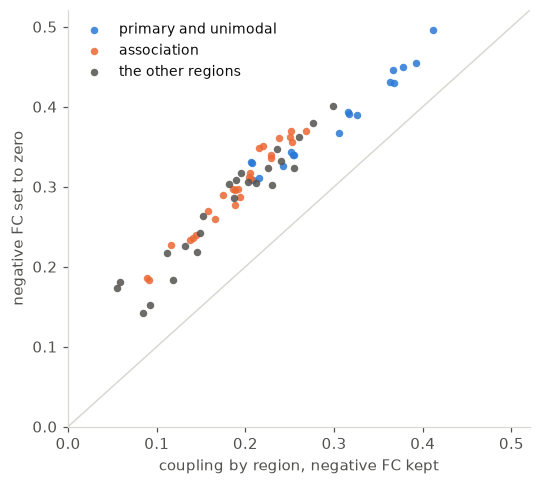

In [11]:
def without_negative(connectome):
    """The same FC with its negative correlations set to zero."""
    return sbci.ContinuousConnectome(np.maximum(connectome.data, 0), connectome.area,
                                     connectome.mask, connectome.metadata)


upper = np.triu_indices(cortex.size, 1)  # the files' condensed order: each pair of vertices once
on = cortex[upper[0]] & cortex[upper[1]]  # the pairs of cortical vertices
del upper
negative = [np.mean(f.data[on] < 0) for f in fc]
smallest = min(float(s.data.min()) for s in sc)
print(f"FC below zero: {min(negative):.0%} to {max(negative):.0%} of the pairs of cortical "
      f"vertices; SC's smallest entry {smallest:.3g}")
below = [np.mean(m[cortex] < 0) for m in coupling]
print(f"negative FC kept: {min(below):.1%} to {max(below):.1%} of a subject's cortical vertices "
      "have negative coupling")

positive = np.vstack([s.coupling(without_negative(f)) for s, f in zip(sc, fc, strict=True)])
higher = positive[:, cortex] > coupling[:, cortex]
means = np.nanmean(positive, axis=1)
print(f"set to zero: coupling higher at {higher.sum():,} of the {higher.size:,} cortical vertices "
      f"of the eleven; the subjects' means {means.min():.3f} to {means.max():.3f}")
r = np.array([np.corrcoef(a[cortex], b[cortex])[0, 1]
              for a, b in zip(coupling, positive, strict=True)])
print(f"each subject's map against its map with negative FC kept: r = {r.min():.3f} to "
      f"{r.max():.3f} (median {np.median(r):.3f})")
positive_map = np.full(cortex.size, np.nan)
positive_map[cortex] = positive[:, cortex].mean(axis=0)
agree = np.corrcoef(mean_map[cortex], positive_map[cortex])[0, 1]
print(f"the eleven's mean maps: r = {agree:.3f}")
regions_positive = extremes(positive_map, "negative FC set to zero")
print(f"primary and unimodal regions {regions_positive[unimodal].mean():.2f} on average, "
      f"association regions {regions_positive[association].mean():.2f}")


def against(before, after, xlabel, ylabel):
    """The 68 regions' mean coupling under two choices, with the line of no change."""
    figure, axis = plt.subplots(figsize=(4.8, 4.3), constrained_layout=True)
    top = max(before.max(), after.max()) * 1.05
    axis.plot([0, top], [0, top], color=RULE, linewidth=1, zorder=0)
    kinds = (("primary and unimodal", unimodal, BLUE), ("association", association, ORANGE),
             ("the other regions", ~unimodal & ~association, MUTED))
    for label, chosen, colour in kinds:
        axis.scatter(before[chosen], after[chosen], s=24, color=colour, alpha=0.85, linewidths=0,
                     label=label)
    axis.set_xlim(0, top)
    axis.set_ylim(0, top)
    axis.set_xlabel(xlabel)
    axis.set_ylabel(ylabel)
    axis.legend(frameon=False, fontsize=9, loc="upper left")
    return figure


figure = against(regions, regions_positive, "coupling by region, negative FC kept",
                 "negative FC set to zero")
plt.show()

## 8. Sensitivity: FC without global signal regression

The released FC has each run's global signal regressed out. Rebuilt from the same runs by
`tools/build_hcp_fc.py --no-gsr`, which keeps it, the FC correlates with the released FC at r =
0.755 to 0.940 subject by subject, and much less of it is negative: 10% to 31% of the pairs of
cortical vertices, against 46% to 53%. Coupling rises, the subjects' means from 0.200-0.268 to
0.244-0.283, and keeps most of its pattern: each subject's map correlates with its map from the
released FC at r = 0.684 to 0.926 (median 0.815), and the eleven's mean maps at 0.856. The subjects'
maps agree with one another a little less, r = 0.50 to 0.64 against 0.53 to 0.71. The occipital
cortex stays highest -- the right lateral occipital cortex 0.38, the right cuneus 0.34, the left
lateral occipital cortex 0.34 and the right pericalcarine cortex 0.33 -- now with the superior
parietal lobule beside it (0.35 and 0.33); the entorhinal cortex (0.09 on both sides) and the caudal
anterior cingulate (0.13 and 0.14) stay lowest, with the temporal pole (0.12 and 0.14). The 68
regions' means under the two models correlate at r = 0.90 (0.92 by rank).

FC nuisance model: HCP minimal preprocessing and ICA-FIX (rfMRI *_Atlas_hp2000_clean); per run, a constant and a linear trend regressed out; grid-vertex mean time series z-scored and the runs concatenated
built from the same runs and frames as the released FC, subject by subject: True


FC without global signal regression against the released: r = 0.755 to 0.940; below zero 10% to 31% of the pairs of cortical vertices


coupling: the subjects' means 0.244 to 0.283
each subject's map against its map from the released FC: r = 0.684 to 0.926 (median 0.815)
the eleven's mean maps: r = 0.856
the subjects' maps against one another: r = 0.50 to 0.64
without global signal regression, highest: RH_lateraloccipital 0.38, RH_superiorparietal 0.35, LH_lateraloccipital 0.34, RH_cuneus 0.34, LH_superiorparietal 0.33, RH_pericalcarine 0.33
without global signal regression, lowest: RH_entorhinal 0.09, LH_entorhinal 0.09, RH_temporalpole 0.12, LH_caudalanteriorcingulate 0.13, RH_caudalanteriorcingulate 0.14, LH_temporalpole 0.14
the 68 regions' means with and without: r = 0.90, by rank 0.92


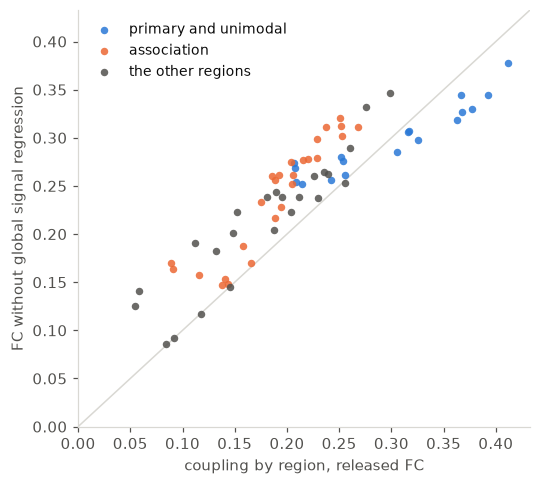

In [12]:
wanted = [NO_GSR / path.name for path in paths[1::2]]  # the same subjects, in the same order
if all(path.exists() for path in wanted):
    rebuilt = [sbci.load(path) for path in wanted]
    assert all((f.mask == cortex).all() for f in rebuilt)
    print("FC nuisance model:", rebuilt[0].metadata.get("fc_nuisance_model"))
    same = all(a.metadata.get(key) == b.metadata.get(key)
               for a, b in zip(fc, rebuilt, strict=True) for key in ("fc_runs", "fc_frames"))
    print(f"built from the same runs and frames as the released FC, subject by subject: {same}")
    r_fc = [np.corrcoef(a.data[on], b.data[on])[0, 1] for a, b in zip(fc, rebuilt, strict=True)]
    negative_rebuilt = [np.mean(f.data[on] < 0) for f in rebuilt]
    print(f"FC without global signal regression against the released: r = {min(r_fc):.3f} to "
          f"{max(r_fc):.3f}; below zero {min(negative_rebuilt):.0%} to "
          f"{max(negative_rebuilt):.0%} of the pairs of cortical vertices")
    no_gsr = np.vstack([s.coupling(f) for s, f in zip(sc, rebuilt, strict=True)])
    means = np.nanmean(no_gsr, axis=1)
    print(f"coupling: the subjects' means {means.min():.3f} to {means.max():.3f}")
    r = np.array([np.corrcoef(a[cortex], b[cortex])[0, 1]
                  for a, b in zip(coupling, no_gsr, strict=True)])
    print(f"each subject's map against its map from the released FC: r = {r.min():.3f} to "
          f"{r.max():.3f} (median {np.median(r):.3f})")
    no_gsr_map = np.full(cortex.size, np.nan)
    no_gsr_map[cortex] = no_gsr[:, cortex].mean(axis=0)
    agree = np.corrcoef(mean_map[cortex], no_gsr_map[cortex])[0, 1]
    print(f"the eleven's mean maps: r = {agree:.3f}")
    r = np.corrcoef(no_gsr[:, cortex])[np.triu_indices(len(sc), 1)]
    print(f"the subjects' maps against one another: r = {r.min():.2f} to {r.max():.2f}")
    regions_no_gsr = extremes(no_gsr_map, "without global signal regression")
    print(f"the 68 regions' means with and without: r = "
          f"{np.corrcoef(regions, regions_no_gsr)[0, 1]:.2f}, by rank "
          f"{spearmanr(regions, regions_no_gsr).statistic:.2f}")
    figure = against(regions, regions_no_gsr, "coupling by region, released FC",
                     "FC without global signal regression")
    plt.show()
else:
    print("This section needs the eleven subjects' FC rebuilt without global signal regression, "
          "which the download does not include: build it from the HCP's resting-state runs with "
          "tools/build_hcp_fc.py --no-gsr (its docstring gives the arguments) and set NO_GSR to "
          "the folder it writes.")

## What this says

- **What coupling compares.** At a vertex, the cosine of its SC and FC profiles: 0.185 at subject
  A's vertex 842 in the left precentral gyrus, 66% of whose inner product comes from that gyrus.
- **Where it is high.** In visual cortex, 0.36 to 0.41 by region in the eleven's mean map, and in
  primary and unimodal cortex generally (0.30 against 0.19 over association regions); lowest in the
  cingulate and entorhinal cortex, 0.05 to 0.09. The subjects share the pattern (r = 0.53 to 0.71
  between their maps).
- **Inside a region.** Across the precentral gyrus it varies nearly as much as between regions (SD
  0.069 and 0.070 against 0.079), rises toward the gyrus's dorsal end and recurs across subjects
  (median r 0.52 and 0.59). Inside association regions it varies a little less than inside unimodal
  ones (SD 0.041 against 0.050), more for its lower level, and recurs less (median r 0.29 against
  0.41).
- **What it is.** A similarity of two profiles, not a mechanism: 63% of the cingulate's gap goes
  with its nearness to the medial wall, where structural connectivity is weak.
- **How robust.** Negative FC set to zero raises coupling everywhere and keeps the pattern (r =
  0.885 to 0.957 per subject); FC without global signal regression raises it and keeps most of the
  pattern (r = 0.684 to 0.926 per subject, 0.856 for the eleven's mean).